# 03.05 — Pré-treinamento australiano da DC-TCN adaptada — Min–Max do treino

**Escopo:** apenas Austrália, pré-treinamento e validação australiana. Nenhum dado brasileiro, fine-tuning ou destilação é utilizado neste notebook.

## Referência e adaptação

- Ren et al. (2024), *A Novel Dual-Channel Temporal Convolutional Network for Photovoltaic Power Forecasting*, *Energies*, 17(3), 698. https://doi.org/10.3390/en17030698.
- A arquitetura usa o conceito de **ramificação multivariada MHA + TCN**, **ramificação univariada TCN** e **fusão**, com uma **cabeça univariada auxiliar** adicionada para a futura transferência ao Brasil. **Não é réplica exata da arquitetura/hiperparâmetros do artigo**.
- Contrato do `03_04`: arquivos `australia_{treino,validacao,teste}_L240_H24.npz`, contendo `X`, `X_potencia`, `y`, `y_kw`, timestamps, nome das variáveis e `capacidade_kw`.
- **Nova normalização**: potência normalizada pelo *mínimo e máximo dos valores usados no treino australiano* (históricos e alvos), sem usar validação ou teste no ajuste. As variáveis meteorológicas mantêm o z-score do `03_04`, calculado no treino.
- **Importante**: o campo `capacidade_kw` do `03_04` será usado **somente para desfazer a antiga divisão por uma referência numérica**. Não pressupomos que esse número seja capacidade nominal verdadeira. Não há vazamento de validação/teste na nova escala.

A previsão permanece **240 horas anteriores → 24 horas futuras**, com emissões horárias, sem meteorologia futura. A avaliação escolhe os checkpoints pela validação australiana e exporta o ramo univariado para uso futuro.


## 1. Ambiente e configuração

Execute em Python com `numpy`, `pandas`, `matplotlib` e `torch`. A GPU CUDA será utilizada automaticamente quando disponível; CPU também é suportada. O batch inicial é conservador para GPUs com pouca VRAM.

In [1]:
from pathlib import Path
import copy
import hashlib
import json
import random
import sys
from datetime import datetime, timezone

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import DataLoader, Dataset
from IPython.display import display

SEED = 42
HISTORICO = 240              # alterar para 24, 48 ou 168 em experimentos posteriores
HORIZONTE = 24
BATCH_SIZE = 16              # se CUDA OOM, usar 8
EPOCAS = 100
PACIENCIA = 12
LEARNING_RATE = 1e-3
WEIGHT_DECAY = 1e-4
LAMBDA_UNI = 0.5            # peso da supervisão auxiliar univariada
HIDDEN_DIM = 64
N_HEADS = 4
N_BLOCOS = 6
KERNEL_SIZE = 3
DROPOUT = 0.10
AVALIAR_TESTE_FINAL = False  # ativar uma única vez após fechar a metodologia

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)
# Priorizar reprodutibilidade, sem prometer igualdade bit-a-bit entre plataformas.
torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False

DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('Python:', sys.version.split()[0], '| PyTorch:', torch.__version__)
print('Dispositivo:', DEVICE)
if DEVICE.type == 'cuda':
    print('GPU:', torch.cuda.get_device_name(0))

CANDIDATAS = [Path.cwd(), *Path.cwd().parents]
RAIZ = next((p for p in CANDIDATAS
             if (p / 'data/processed/sequencias_temporais_24h').is_dir()), None)
if RAIZ is None:
    raise FileNotFoundError(
        'Pasta data/processed/sequencias_temporais_24h não localizada. '
        'Execute o 03_04 e abra o notebook dentro do projeto (ou de subpasta).'
    )
TENSORES = RAIZ / 'data/processed/sequencias_temporais_24h'
SAIDA = RAIZ / 'reports/tcc/03_05_pre_treinamento_dc_tcn' / f'L{HISTORICO}_H{HORIZONTE}_minmax_treino_seed{SEED}'
SAIDA.mkdir(parents=True, exist_ok=True)
print('Dados:', TENSORES)
print('Saídas:', SAIDA)

Python: 3.14.2 | PyTorch: 2.14.1+cu126
Dispositivo: cuda
GPU: NVIDIA GeForce RTX 3050 Laptop GPU
Dados: c:\Users\Camille\Documents\UFJF\TCC\Leopoldo\data\processed\sequencias_temporais_24h
Saídas: c:\Users\Camille\Documents\UFJF\TCC\Leopoldo\reports\tcc\03_05_pre_treinamento_dc_tcn\L240_H24_minmax_treino_seed42


## 2. Carregar tensores e ajustar Min–Max **somente no treino**

O `03_04` já fez o tratamento, construiu as janelas e normalizou as variáveis meteorológicas com estatísticas do treino. Aqui, desfazemos apenas a antiga normalização da **potência**, utilizando o fator armazenado no NPZ como fator matemático de recuperação: `potencia_kw = X_potencia * capacidade_kw` e `y_kw` para os alvos.

**Intervalo usado para o Min–Max:** todas as horas de histórico e alvo que efetivamente participam das janelas de **treinamento australianas**, sem incluir uma única observação da validação ou do teste. As janelas se sobrepõem, mas isso não altera seus valores mínimo e máximo. A mesma escala é aplicada à validação/teste sem reajuste nem clipping; valores fora de [0, 1] podem ocorrer.


In [2]:
FEATURES_ESPERADAS = [
    'Global_Horizontal_Radiation',
    'Weather_Temperature_Celsius',
    'Weather_Relative_Humidity',
    'Wind_Speed',
    'Active_Power',
]


def sha256(path):
    h = hashlib.sha256()
    with Path(path).open('rb') as f:
        for bloco in iter(lambda: f.read(1024 * 1024), b''):
            h.update(bloco)
    return h.hexdigest()


def carregar_particao(particao):
    if particao not in {'treino', 'validacao', 'teste'}:
        raise ValueError(f'Partição inválida: {particao}')
    path = TENSORES / f'australia_{particao}_L{HISTORICO}_H{HORIZONTE}.npz'
    if not path.is_file():
        raise FileNotFoundError(f'Arquivo ausente: {path}. Execute o 03_04.')
    with np.load(path, allow_pickle=False) as z:
        chaves = {'X', 'X_potencia', 'y', 'y_kw', 'features', 'capacidade_kw',
                  'timestamps_X', 'timestamps_y', 'emissao', 'mask_y_observado'}
        if chaves - set(z.files):
            raise ValueError(f'{path.name}: chaves ausentes: {chaves - set(z.files)}')
        pacote = {k: z[k].copy() for k in z.files}
    x, xp, y = pacote['X'], pacote['X_potencia'], pacote['y']
    if x.ndim != 3 or x.shape[1:] != (HISTORICO, len(FEATURES_ESPERADAS)):
        raise ValueError(f'X com formato inesperado: {x.shape}')
    if xp.shape != (len(x), HISTORICO, 1) or y.shape != (len(x), HORIZONTE):
        raise ValueError('X_potencia ou y com dimensão diferente da esperada')
    if list(pacote['features']) != FEATURES_ESPERADAS:
        raise ValueError('Ordem de features não corresponde à versão esperada do 03_04')
    if not np.isfinite(x).all() or not np.isfinite(xp).all() or not np.isfinite(y).all() or not np.isfinite(pacote['y_kw']).all():
        raise ValueError('Valores não finitos encontrados')
    if not np.all(pacote['mask_y_observado']):
        raise ValueError('Há alvos não observados')
    if not np.allclose(xp[:, :, 0], x[:, :, -1], rtol=1e-6, atol=1e-6):
        raise ValueError('Canal de potência não coincide entre X e X_potencia')
    fator_antigo = float(pacote['capacidade_kw'])
    if not np.isfinite(fator_antigo) or fator_antigo <= 0:
        raise ValueError('Fator antigo do 03_04 inválido')
    if not np.allclose(y.astype(np.float64) * fator_antigo, pacote['y_kw'], rtol=3e-5, atol=1e-4):
        raise ValueError('O NPZ não obedece à normalização anterior; abortando para evitar reescala incorreta')
    if len(x):
        if not np.all(pacote['timestamps_X'][:, -1] + np.timedelta64(1, 'h') == pacote['emissao']):
            raise ValueError('Emissões fora do contrato')
        if not np.all(pacote['timestamps_y'][:, 0] == pacote['emissao']):
            raise ValueError('Timestamps dos alvos incorretos')
        if not np.all(np.diff(pacote['timestamps_X'], axis=1) == np.timedelta64(1, 'h')):
            raise ValueError('Lacuna temporal em X')
        if not np.all(np.diff(pacote['timestamps_y'], axis=1) == np.timedelta64(1, 'h')):
            raise ValueError('Lacuna temporal em y')
    pacote['fator_original_03_04_kw'] = fator_antigo
    pacote['arquivo'] = str(path)
    pacote['hash_sha256'] = sha256(path)
    return pacote


# Nunca ler o TESTE nesta etapa: opção AVALIAR_TESTE_FINAL só age ao final do notebook.
train = carregar_particao('treino')
val = carregar_particao('validacao')
if len(train['X']) == 0 or len(val['X']) == 0:
    raise ValueError('Treino ou validação vazios para o histórico selecionado.')
if train['fator_original_03_04_kw'] != val['fator_original_03_04_kw']:
    raise ValueError('Escalas originais diferentes nas duas partições')
if not np.max(train['timestamps_y']) < np.min(val['timestamps_y']):
    raise ValueError('Alvos das partições fora de ordem cronológica')

# Usa exclusivamente os valores que participam das janelas de TREINO.
# Histórico está em unidades "X/escala_antiga"; alvos y_kw já estão em kW.
fator = train['fator_original_03_04_kw']
pmin = min(float(train['X_potencia'].min()) * fator, float(train['y_kw'].min()))
pmax = max(float(train['X_potencia'].max()) * fator, float(train['y_kw'].max()))
amplitude = pmax - pmin
if not np.isfinite(amplitude) or amplitude <= 1e-8:
    raise ValueError('Intervalo de potência do treino degenerado: Min–Max não é aplicável')
NORMALIZACAO = {
    'metodo': 'minmax_somente_treino_australia',
    'min_kw': pmin,
    'max_kw': pmax,
    'amplitude_kw': amplitude,
    'origem_minmax': 'X_potencia e y_kw dos arquivos de treino do 03_04',
    'fator_desfazer_03_04_kw': fator,
    'avaliacao_fora_intervalo': 'nao_clipa',
}


def aplicar_minmax_treino(pacote):
    # Mantém GHI, temperatura, umidade e vento como no 03_04 (z-score do treino).
    # Reconstrói somente a potência real usada antes da divisão no 03_04.
    x = np.ascontiguousarray(pacote['X'].copy(), dtype=np.float32)
    potencia_kw = pacote['X_potencia'][:, :, 0].astype(np.float64) * pacote['fator_original_03_04_kw']
    nova_potencia = ((potencia_kw - pmin) / amplitude).astype(np.float32)
    x[:, :, -1] = nova_potencia
    pacote['X'] = x
    pacote['X_potencia'] = nova_potencia[:, :, None].copy()
    pacote['y'] = ((pacote['y_kw'].astype(np.float64) - pmin) / amplitude).astype(np.float32)
    # Auditoria da transformação inversa, em kW.
    if not np.allclose(pacote['y'].astype(np.float64) * amplitude + pmin,
                       pacote['y_kw'], rtol=3e-5, atol=1e-4):
        raise ValueError('Falha no roundtrip de y_kw')
    return pacote


train = aplicar_minmax_treino(train)
val = aplicar_minmax_treino(val)
print('Potência: Min–Max calculado EXCLUSIVAMENTE nas janelas do TREINO australiano')
print(f'Mínimo={pmin:.4f} kW | máximo={pmax:.4f} kW | amplitude={amplitude:.4f} kW')
print('Antigo fator do 03_04 usado apenas para RECONSTRUIR potência:', fator)
print('Faixa dos alvos normalizados do treino:', float(train['y'].min()), float(train['y'].max()))
print('Faixa dos alvos normalizados da validação:', float(val['y'].min()), float(val['y'].max()))
display(pd.DataFrame([
    dict(particao=p, amostras=len(d['X']), X=str(d['X'].shape),
         X_potencia=str(d['X_potencia'].shape), y=str(d['y'].shape),
         primeiro_alvo=str(d['timestamps_y'].min()), ultimo_alvo=str(d['timestamps_y'].max()))
    for p, d in [('treino', train), ('validacao', val)]
]))
print('Features:', list(train['features']))
(SAIDA / 'normalizacao_potencia_treino.json').write_text(
    json.dumps(NORMALIZACAO, ensure_ascii=False, indent=2), encoding='utf-8'
)


Potência: Min–Max calculado EXCLUSIVAMENTE nas janelas do TREINO australiano
Mínimo=0.0000 kW | máximo=21.6269 kW | amplitude=21.6269 kW
Antigo fator do 03_04 usado apenas para RECONSTRUIR potência: 24.0
Faixa dos alvos normalizados do treino: 0.0 1.0
Faixa dos alvos normalizados da validação: 0.0 0.9194962382316589


,particao,amostras,X,X_potencia,y,primeiro_alvo,ultimo_alvo
0,treino,5160,"(5160, 240, 5)","(5160, 240, 1)","(5160, 24)",2013-08-07T05:00:00.000000,2015-10-04T00:00:00.000000
1,validacao,1503,"(1503, 240, 5)","(1503, 240, 1)","(1503, 24)",2015-10-14T01:00:00.000000,2016-03-25T00:00:00.000000


Features: [np.str_('Global_Horizontal_Radiation'), np.str_('Weather_Temperature_Celsius'), np.str_('Weather_Relative_Humidity'), np.str_('Wind_Speed'), np.str_('Active_Power')]


284

## 3. Dataset e DataLoaders

Os datasets recebem os mesmos três tensores `X`, `X_potencia` e `y`, agora com a potência em Min–Max do treino. A meteorologia continua com o z-score original do `03_04`. Não há alterações nos arquivos NPZ de origem.


In [3]:
class DatasetAustraliano(Dataset):
    def __init__(self, pacote):
        self.x = torch.from_numpy(np.ascontiguousarray(pacote['X'], dtype=np.float32))
        self.x_p = torch.from_numpy(np.ascontiguousarray(pacote['X_potencia'], dtype=np.float32))
        self.y = torch.from_numpy(np.ascontiguousarray(pacote['y'], dtype=np.float32))
    def __len__(self):
        return len(self.y)
    def __getitem__(self, i):
        return self.x[i], self.x_p[i], self.y[i]

loader_train = DataLoader(DatasetAustraliano(train), batch_size=BATCH_SIZE,
                          shuffle=True, num_workers=0, pin_memory=(DEVICE.type == 'cuda'))
loader_val = DataLoader(DatasetAustraliano(val), batch_size=BATCH_SIZE,
                        shuffle=False, num_workers=0, pin_memory=(DEVICE.type == 'cuda'))
print('Batches:', len(loader_train), '(treino),', len(loader_val), '(validação)')

Batches: 323 (treino), 94 (validação)


## 4. Modelo DC-TCN com cabeça univariada auxiliar

A arquitetura segue a **ideia de canais do artigo**, com ajustes explícitos para o experimento de Transfer Learning:

1. **Multivariado:** projeção `5→64`, MHA temporal (4 cabeças), TCN causal residual e vetor final.
2. **Univariado:** projeção `1→64`, TCN causal residual e vetor final.
3. **Fusão:** concatenação dos dois vetores seguida de MLP para **24 previsões**.
4. **Cabeça auxiliar:** MLP independente, alimentado **somente pelo vetor univariado**, também prevendo 24 valores. Essa cabeça e seu encoder poderão ser reutilizados no futuro com dados brasileiros.

As seis dilatações `[1, 2, 4, 8, 16, 32]`, com duas convoluções de kernel 3 por bloco, fornecem campo receptivo teórico de **253 horas**. A atenção opera **apenas no histórico**, nunca nos 24 valores-alvo. O artigo original apresenta uma fusão por camadas densas; este código **não reproduz literalmente todos os detalhes e hiperparâmetros** de Ren et al.

In [4]:
class ConvCausal(nn.Module):
    def __init__(self, canais, kernel, dilatacao):
        super().__init__()
        self.pad_esquerdo = (kernel - 1) * dilatacao
        self.conv = nn.Conv1d(canais, canais, kernel_size=kernel, dilation=dilatacao)
    def forward(self, x):
        return self.conv(F.pad(x, (self.pad_esquerdo, 0)))


class BlocoTCN(nn.Module):
    def __init__(self, canais, kernel, dilatacao, dropout):
        super().__init__()
        self.conv1 = ConvCausal(canais, kernel, dilatacao)
        self.conv2 = ConvCausal(canais, kernel, dilatacao)
        self.norm1 = nn.LayerNorm(canais)
        self.norm2 = nn.LayerNorm(canais)
        self.dropout = nn.Dropout(dropout)

    def forward(self, x):
        # x: [B, C, T]. LayerNorm normaliza somente canais em cada instante.
        h = self.conv1(x).transpose(1, 2)
        h = self.dropout(F.gelu(self.norm1(h))).transpose(1, 2)
        h = self.conv2(h).transpose(1, 2)
        h = self.dropout(F.gelu(self.norm2(h))).transpose(1, 2)
        return x + h


class EncoderTemporal(nn.Module):
    def __init__(self, n_features, dim, n_blocos, kernel, dropout, usa_atencao=False, n_heads=4):
        super().__init__()
        self.proj = nn.Linear(n_features, dim)
        self.usa_atencao = usa_atencao
        if usa_atencao:
            self.atencao = nn.MultiheadAttention(dim, n_heads, dropout=dropout, batch_first=True)
            self.norm_att = nn.LayerNorm(dim)
        self.tcn = nn.Sequential(*[
            BlocoTCN(dim, kernel, 2**i, dropout) for i in range(n_blocos)
        ])

    def forward(self, x):
        # x: [B, T, features]; toda a janela é histórica e conhecida na emissão.
        x = self.proj(x)
        if self.usa_atencao:
            att, _ = self.atencao(x, x, x, need_weights=False)
            x = self.norm_att(x + att)
        z = self.tcn(x.transpose(1, 2)).transpose(1, 2)
        return z[:, -1, :]  # representação da última hora histórica


class PrevisorUnivariado(nn.Module):
    def __init__(self, dim, n_blocos, kernel, dropout, horizonte):
        super().__init__()
        self.encoder = EncoderTemporal(1, dim, n_blocos, kernel, dropout)
        self.cabeca = nn.Sequential(nn.Linear(dim, dim), nn.GELU(),
                                   nn.Dropout(dropout), nn.Linear(dim, horizonte))
    def forward(self, x_potencia):
        return self.cabeca(self.encoder(x_potencia))


class DCTCNAdaptada(nn.Module):
    def __init__(self, n_features, dim=64, n_heads=4, n_blocos=6,
                 kernel=3, dropout=0.1, horizonte=24):
        super().__init__()
        self.multi_encoder = EncoderTemporal(n_features, dim, n_blocos, kernel,
                                             dropout, usa_atencao=True, n_heads=n_heads)
        self.uni_model = PrevisorUnivariado(dim, n_blocos, kernel, dropout, horizonte)
        self.fusao = nn.Sequential(nn.Linear(dim * 2, dim), nn.GELU(),
                                  nn.Dropout(dropout), nn.Linear(dim, horizonte))

    def forward(self, x_multi, x_potencia):
        z_multi = self.multi_encoder(x_multi)
        z_uni = self.uni_model.encoder(x_potencia)
        y_fusao = self.fusao(torch.cat([z_multi, z_uni], dim=-1))
        y_uni = self.uni_model.cabeca(z_uni)
        return y_fusao, y_uni


def construir_modelo():
    return DCTCNAdaptada(n_features=len(FEATURES_ESPERADAS), dim=HIDDEN_DIM,
                        n_heads=N_HEADS, n_blocos=N_BLOCOS, kernel=KERNEL_SIZE,
                        dropout=DROPOUT, horizonte=HORIZONTE)

modelo = construir_modelo().to(DEVICE)
n_params = sum(p.numel() for p in modelo.parameters())
print(f'Parâmetros treináveis: {n_params:,}'.replace(',', '.'))
print('Campo receptivo da TCN:', 1 + 2 * (KERNEL_SIZE-1) * sum(2**i for i in range(N_BLOCOS)))

# Teste de formato + backprop antes do treinamento real.
teste_multi = torch.zeros(2, HISTORICO, len(FEATURES_ESPERADAS), device=DEVICE)
teste_uni = torch.zeros(2, HISTORICO, 1, device=DEVICE)
y_f, y_u = modelo(teste_multi, teste_uni)
assert y_f.shape == (2, HORIZONTE) and y_u.shape == (2, HORIZONTE)
modelo.zero_grad(set_to_none=True)
(y_f.mean() + y_u.mean()).backward()
assert any(p.grad is not None for p in modelo.uni_model.parameters())
print('Passagem direta/gradientes: OK')
del teste_multi, teste_uni, y_f, y_u

Parâmetros treináveis: 332.336
Campo receptivo da TCN: 253
Passagem direta/gradientes: OK


## 5. Treinamento conjunto das saídas

A DC-TCN produz a previsão da **fusão** e a previsão **univariada auxiliar**. Otimizamos a soma da Huber da fusão e da Huber univariada ponderada por `LAMBDA_UNI`. Checkpoints escolhidos exclusivamente pela validação australiana. As perdas e os MAEs são agora calculados em unidades *Min–Max* (não em p.u. de capacidade instalada).


In [5]:
criterio = nn.HuberLoss(delta=0.05)
otimizador = torch.optim.AdamW(modelo.parameters(), lr=LEARNING_RATE,
                               weight_decay=WEIGHT_DECAY)
# Scheduler baseado na validação total, sem informações de teste.
scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
    otimizador, mode='min', factor=0.5, patience=5, min_lr=1e-5)


def epoca(loader, treinamento=False):
    modelo.train(treinamento)
    somas = {'loss_total': 0.0, 'loss_fusao': 0.0, 'loss_uni': 0.0,
             'mae_fusao': 0.0, 'mae_uni': 0.0}
    n_amostras = 0
    contexto = torch.enable_grad() if treinamento else torch.no_grad()
    with contexto:
        for x, xp, y in loader:
            x = x.to(DEVICE, non_blocking=True)
            xp = xp.to(DEVICE, non_blocking=True)
            y = y.to(DEVICE, non_blocking=True)
            if treinamento:
                otimizador.zero_grad(set_to_none=True)
            pred_f, pred_u = modelo(x, xp)
            lf = criterio(pred_f, y)
            lu = criterio(pred_u, y)
            loss = lf + LAMBDA_UNI * lu
            if treinamento:
                loss.backward()
                torch.nn.utils.clip_grad_norm_(modelo.parameters(), max_norm=1.0)
                otimizador.step()
            b = len(y)
            n_amostras += b
            somas['loss_total'] += loss.item() * b
            somas['loss_fusao'] += lf.item() * b
            somas['loss_uni'] += lu.item() * b
            somas['mae_fusao'] += torch.abs(pred_f-y).mean().item() * b
            somas['mae_uni'] += torch.abs(pred_u-y).mean().item() * b
    return {k: v/n_amostras for k, v in somas.items()}


def checkpoint(arquivo, epoca_num, metrica, tipo):
    torch.save({
        'model_state_dict': copy.deepcopy(modelo.state_dict()),
        'epoch': int(epoca_num), 'selection_metric': float(metrica),
        'selection_type': tipo,
        'config': dict(hist=HISTORICO, horizonte=HORIZONTE,
                       n_features=len(FEATURES_ESPERADAS), dim=HIDDEN_DIM,
                       heads=N_HEADS, blocks=N_BLOCOS, kernel=KERNEL_SIZE,
                       dropout=DROPOUT, lambda_uni=LAMBDA_UNI,
                       normalizacao_potencia=NORMALIZACAO,
                       features=FEATURES_ESPERADAS, seed=SEED),
        'source': 'australia',
    }, arquivo)

historico_treino = []
melhor_total = float('inf')
melhor_fusao = float('inf')
melhor_uni = float('inf')
epocas_sem_melhora = 0

for ep in range(1, EPOCAS + 1):
    treino = epoca(loader_train, treinamento=True)
    validacao = epoca(loader_val, treinamento=False)
    scheduler.step(validacao['loss_total'])
    row = {'epoca': ep, 'lr': otimizador.param_groups[0]['lr']}
    row.update({'train_' + k: v for k, v in treino.items()})
    row.update({'val_' + k: v for k, v in validacao.items()})
    historico_treino.append(row)

    if validacao['loss_fusao'] < melhor_fusao - 1e-8:
        melhor_fusao = validacao['loss_fusao']
        checkpoint(SAIDA/'best_fusao.pt', ep, melhor_fusao, 'val_loss_fusao')
    if validacao['loss_uni'] < melhor_uni - 1e-8:
        melhor_uni = validacao['loss_uni']
        checkpoint(SAIDA/'best_univariado_completo.pt', ep, melhor_uni, 'val_loss_uni')
    if validacao['loss_total'] < melhor_total - 1e-8:
        melhor_total = validacao['loss_total']
        epocas_sem_melhora = 0
    else:
        epocas_sem_melhora += 1

    if ep == 1 or ep % 5 == 0 or epocas_sem_melhora >= PACIENCIA:
        print(f"ep {ep:03d} | loss treino={treino['loss_total']:.5f} "
              f"val={validacao['loss_total']:.5f} "
              f"| MAE val fusão={validacao['mae_fusao']:.4f} "
              f"uni={validacao['mae_uni']:.4f} | LR={row['lr']:.1e}")
    pd.DataFrame(historico_treino).to_csv(SAIDA/'historico_treinamento.csv', index=False)
    if epocas_sem_melhora >= PACIENCIA:
        print('Early stopping na época', ep)
        break

historico_df = pd.DataFrame(historico_treino)
display(historico_df.tail(8))
print('Melhor loss de validação — fusão:', melhor_fusao)
print('Melhor loss de validação — univariado:', melhor_uni)

ep 001 | loss treino=0.00869 val=0.00526 | MAE val fusão=0.0901 uni=0.0873 | LR=1.0e-03
ep 005 | loss treino=0.00397 val=0.00420 | MAE val fusão=0.0744 uni=0.0695 | LR=1.0e-03
ep 010 | loss treino=0.00331 val=0.00399 | MAE val fusão=0.0695 uni=0.0684 | LR=1.0e-03
ep 015 | loss treino=0.00307 val=0.00392 | MAE val fusão=0.0693 uni=0.0652 | LR=1.0e-03
ep 020 | loss treino=0.00288 val=0.00383 | MAE val fusão=0.0672 uni=0.0653 | LR=1.0e-03
ep 025 | loss treino=0.00277 val=0.00402 | MAE val fusão=0.0717 uni=0.0654 | LR=1.0e-03
ep 030 | loss treino=0.00254 val=0.00388 | MAE val fusão=0.0684 uni=0.0638 | LR=5.0e-04
ep 035 | loss treino=0.00244 val=0.00380 | MAE val fusão=0.0667 uni=0.0632 | LR=5.0e-04
ep 040 | loss treino=0.00239 val=0.00390 | MAE val fusão=0.0688 uni=0.0625 | LR=5.0e-04
ep 045 | loss treino=0.00229 val=0.00377 | MAE val fusão=0.0657 uni=0.0627 | LR=2.5e-04
ep 050 | loss treino=0.00228 val=0.00384 | MAE val fusão=0.0672 uni=0.0630 | LR=2.5e-04
ep 055 | loss treino=0.00222 val

,epoca,lr,train_loss_total,train_loss_fusao,train_loss_uni,train_mae_fusao,train_mae_uni,val_loss_total,val_loss_fusao,val_loss_uni,val_mae_fusao,val_mae_uni
49,50,0.000250,0.002279,0.001344,0.001871,0.042921,0.054278,0.003836,0.002618,0.002436,0.067187,0.063043
50,51,0.000125,0.002269,0.001337,0.001865,0.042781,0.054167,0.003842,0.002644,0.002397,0.067608,0.062114
51,52,0.000125,0.002237,0.001319,0.001837,0.042306,0.053485,0.003798,0.002594,0.002407,0.066499,0.062151
52,53,0.000125,0.002214,0.001307,0.001814,0.042066,0.052985,0.003782,0.002588,0.002388,0.066229,0.061750
53,54,0.000125,0.002205,0.001291,0.001827,0.041666,0.053252,0.003819,0.002630,0.002379,0.067019,0.061514
54,55,0.000125,0.002215,0.001307,0.001816,0.042028,0.053026,0.003798,0.002590,0.002416,0.066180,0.062296
55,56,0.000125,0.002195,0.001291,0.001809,0.041683,0.052866,0.003789,0.002579,0.002420,0.066010,0.062522
56,57,0.000063,0.002209,0.001300,0.001817,0.041872,0.053121,0.003813,0.002612,0.002400,0.066732,0.062033


Melhor loss de validação — fusão: 0.002561756296542486
Melhor loss de validação — univariado: 0.002378960032735134


## 6. Carregar os dois melhores modelos e exportar o ramo univariado

O primeiro checkpoint representa a DC-TCN completa. O segundo é selecionado pelo desempenho do ramo univariado e exportado em **um arquivo independente**, com encoder e cabeça de 24 horas, pronto para futura inicialização do fine-tuning brasileiro. Este notebook **não realiza** essa transferência.

In [6]:
def carregar_checkpoint(path):
    # Checkpoint produzido somente por este notebook. Não carregue checkpoints de fontes não confiáveis.
    ckpt = torch.load(path, map_location=DEVICE, weights_only=True)
    m = construir_modelo().to(DEVICE)
    m.load_state_dict(ckpt['model_state_dict'])
    m.eval()
    return m, ckpt

modelo_fusao, c_fusao = carregar_checkpoint(SAIDA/'best_fusao.pt')
modelo_uni, c_uni = carregar_checkpoint(SAIDA/'best_univariado_completo.pt')

# Checkpoint estritamente independente de meteorologia: encoder + cabeça da potência.
student = PrevisorUnivariado(HIDDEN_DIM, N_BLOCOS, KERNEL_SIZE, DROPOUT, HORIZONTE)
student.load_state_dict(modelo_uni.uni_model.state_dict())
student.eval()
torch.save({
    'model_state_dict': student.state_dict(),
    'architecture': 'PrevisorUnivariado',
    'config': c_uni['config'],
    'best_epoch_australia': c_uni['epoch'],
    'selected_on': c_uni['selection_type'],
    'note': 'Pré-treinamento univariado auxiliar; ainda NÃO submetido a distillation/fine-tuning.',
}, SAIDA/'pre_treinado_univariado_para_tl.pt')
print('Melhor época da fusão:', c_fusao['epoch'])
print('Melhor época do univariado:', c_uni['epoch'])
print('Arquivo para uso futuro:', SAIDA/'pre_treinado_univariado_para_tl.pt')

# Verificação de que o checkpoint exportado não precisa de meteorologia.
student = student.to(DEVICE)
with torch.no_grad():
    y_student = student(torch.from_numpy(val['X_potencia'][:2].copy()).to(DEVICE))
assert tuple(y_student.shape) == (2, HORIZONTE)
print('Ramo univariado independente: OK')

Melhor época da fusão: 45
Melhor época do univariado: 54
Arquivo para uso futuro: c:\Users\Camille\Documents\UFJF\TCC\Leopoldo\reports\tcc\03_05_pre_treinamento_dc_tcn\L240_H24_minmax_treino_seed42\pre_treinado_univariado_para_tl.pt
Ramo univariado independente: OK


## 7. Avaliação na validação australiana e gráficos

Métricas normalizadas correspondem **ao intervalo Min–Max do treino**; erros em kW são calculados após a inversão `P_kW = p_norm × (max_treino - min_treino) + min_treino`. **Não** usar a escala antiga `capacidade_kw` para calcular métricas.


,modelo,MAE_norm_minmax,RMSE_norm_minmax,MAE_kW,RMSE_kW,BIAS_kW,R2
0,DC-TCN_fusao,0.065731,0.123948,1.421562,2.680616,-0.175128,0.881292
1,TCN_univariada_auxiliar,0.061514,0.121800,1.330361,2.634148,0.138943,0.885372


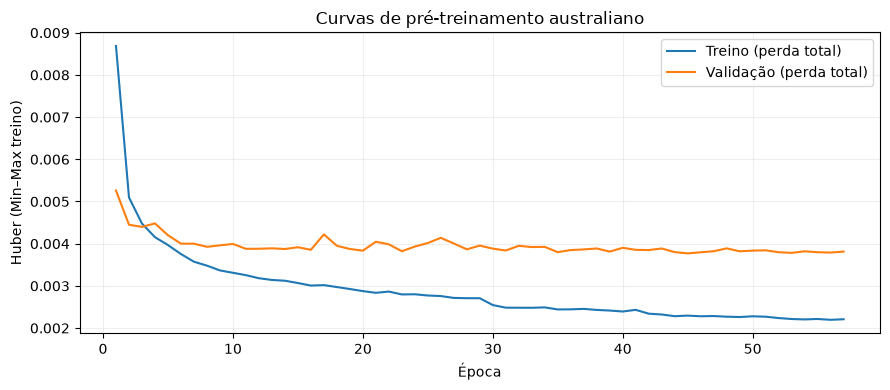

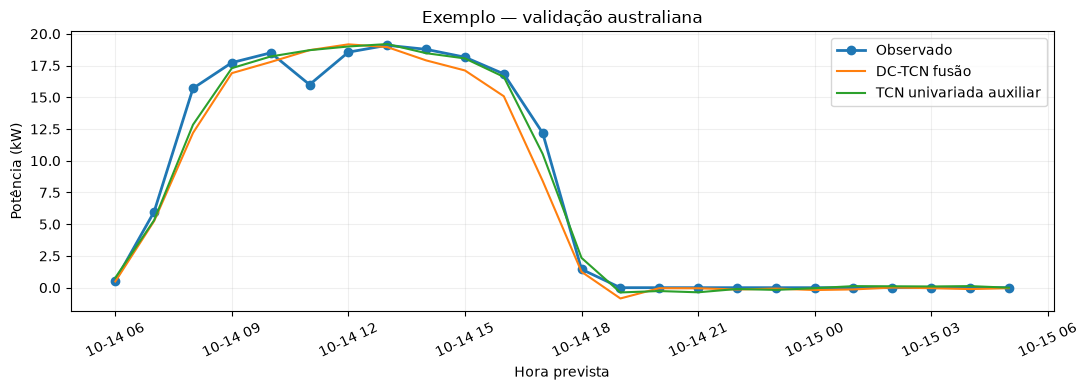

In [7]:
@torch.no_grad()
def prever(modelo_avaliado, pacote, modo, batch_size=BATCH_SIZE):
    modelo_avaliado.eval()
    ds = DatasetAustraliano(pacote)
    loader = DataLoader(ds, batch_size=batch_size, shuffle=False, num_workers=0)
    preds = []
    for x, xp, _ in loader:
        x, xp = x.to(DEVICE), xp.to(DEVICE)
        if modo == 'fusao':
            pred = modelo_avaliado(x, xp)[0]
        elif modo == 'univariado':
            pred = modelo_avaliado.uni_model(xp)
        else:
            raise ValueError(modo)
        preds.append(pred.cpu().numpy())
    return np.concatenate(preds, axis=0)


def desnormalizar_potencia(p):
    return np.asarray(p, dtype=np.float64) * amplitude + pmin


def metricas(p, y):
    # Calcula as métricas físicas após inversão correta do Min–Max do treino.
    pred_kw, real_kw = desnormalizar_potencia(p), desnormalizar_potencia(y)
    erro = pred_kw - real_kw
    mae_kw = float(np.mean(np.abs(erro)))
    rmse_kw = float(np.sqrt(np.mean(erro**2)))
    bias_kw = float(np.mean(erro))
    den = float(np.sum((real_kw - np.mean(real_kw))**2))
    r2 = 1 - float(np.sum(erro**2)) / den if den > 1e-12 else np.nan
    return dict(MAE_norm_minmax=mae_kw / amplitude,
                RMSE_norm_minmax=rmse_kw / amplitude,
                MAE_kW=mae_kw, RMSE_kW=rmse_kw, BIAS_kW=bias_kw, R2=r2)

pred_fusao = prever(modelo_fusao, val, 'fusao')
pred_uni = prever(modelo_uni, val, 'univariado')
resultado_val = pd.DataFrame([
    {'modelo': 'DC-TCN_fusao', **metricas(pred_fusao, val['y'])},
    {'modelo': 'TCN_univariada_auxiliar', **metricas(pred_uni, val['y'])},
])
display(resultado_val)
resultado_val.to_csv(SAIDA/'metricas_validacao_australia.csv', index=False)

fig, ax = plt.subplots(figsize=(9, 4))
ax.plot(historico_df.epoca, historico_df.train_loss_total, label='Treino (perda total)')
ax.plot(historico_df.epoca, historico_df.val_loss_total, label='Validação (perda total)')
ax.set(xlabel='Época', ylabel='Huber (Min–Max treino)', title='Curvas de pré-treinamento australiano')
ax.grid(alpha=.2)
ax.legend()
fig.tight_layout()
fig.savefig(SAIDA/'curvas_treino.png', dpi=160)
plt.show()

# Exemplo ilustrativo de UMA previsão de 24h da validação.
idx = min(5, len(val['y']) - 1)
tempo = pd.to_datetime(val['timestamps_y'][idx])
fig, ax = plt.subplots(figsize=(11, 4))
ax.plot(tempo, val['y_kw'][idx], 'o-', label='Observado', linewidth=2)
ax.plot(tempo, desnormalizar_potencia(pred_fusao[idx]), label='DC-TCN fusão')
ax.plot(tempo, desnormalizar_potencia(pred_uni[idx]), label='TCN univariada auxiliar')
ax.set(xlabel='Hora prevista', ylabel='Potência (kW)', title='Exemplo — validação australiana')
ax.tick_params(axis='x', rotation=25)
ax.grid(alpha=.2)
ax.legend()
fig.tight_layout()
fig.savefig(SAIDA/'exemplo_previsao_validacao.png', dpi=160)
plt.show()

## 8. Teste australiano FINAL — opcional

Por padrão, permanece desligado. Quando ativado, o pacote de teste é lido **depois** da seleção final do modelo e normalizado exclusivamente com o Min–Max previamente definido no treino, sem reajuste dos extremos.


In [8]:
if AVALIAR_TESTE_FINAL:
    teste = aplicar_minmax_treino(carregar_particao('teste'))
    resultado_teste = pd.DataFrame([
        {'modelo': 'DC-TCN_fusao',
         **metricas(prever(modelo_fusao, teste, 'fusao'), teste['y'])},
        {'modelo': 'TCN_univariada_auxiliar',
         **metricas(prever(modelo_uni, teste, 'univariado'), teste['y'])},
    ])
    display(resultado_teste)
    resultado_teste.to_csv(SAIDA/'metricas_teste_australia_FINAL.csv', index=False)
else:
    print('Teste australiano preservado. AVALIAR_TESTE_FINAL=False')

Teste australiano preservado. AVALIAR_TESTE_FINAL=False


## 9. Manifesto de reprodutibilidade

O manifesto registra os arquivos de origem, versões, normalização Min–Max **apenas do treino**, hiperparâmetros e checkpoints. Na etapa brasileira, será necessário calcular o Min–Max usando **somente o treino brasileiro** e aplicar essa escala às partições brasileiras; não se deve reutilizar automaticamente o mínimo e máximo físicos australianos no Brasil.


In [9]:
manifesto = {
    'objetivo': 'Pre-treinamento australiano de DC-TCN adaptada, sem fine-tuning brasileiro',
    'artigo_base': 'Ren et al., Energies 2024, DOI 10.3390/en17030698',
    'adaptacao': 'Cabeca auxiliar univariada supervisionada; nao e replica exata do artigo',
    'data_utc': datetime.now(timezone.utc).isoformat(),
    'dispositivo': str(DEVICE),
    'pytorch': torch.__version__,
    'fonte': 'Australia, tensores do 03_04',
    'arquivos_fonte': {
        'treino': {'path': train['arquivo'], 'sha256': train['hash_sha256']},
        'validacao': {'path': val['arquivo'], 'sha256': val['hash_sha256']},
    },
    'config': c_uni['config'],
    'hiperparametros': {'batch': BATCH_SIZE, 'epocas_max': EPOCAS, 'paciencia': PACIENCIA,
                       'learning_rate': LEARNING_RATE, 'weight_decay': WEIGHT_DECAY,
                       'huber_delta': 0.05},
    'amostras': {'treino': len(train['X']), 'validacao': len(val['X'])},
    'melhor_epoca_fusao': c_fusao['epoch'],
    'melhor_epoca_univariado': c_uni['epoch'],
    'normalizacao_potencia': NORMALIZACAO,
    'capacidade_nominal_utilizada': False,
    'teste_final_executado': bool(AVALIAR_TESTE_FINAL),
    'arquivos_gerados': ['best_fusao.pt', 'best_univariado_completo.pt',
                         'pre_treinado_univariado_para_tl.pt',
                         'historico_treinamento.csv', 'metricas_validacao_australia.csv',
                         'normalizacao_potencia_treino.json',
                         'curvas_treino.png', 'exemplo_previsao_validacao.png'],
}
(SAIDA/'manifesto.json').write_text(json.dumps(manifesto, indent=2, ensure_ascii=False), encoding='utf-8')
print('Pré-treinamento concluído. Outputs:', SAIDA)
print('Para transferência futura:', SAIDA/'pre_treinado_univariado_para_tl.pt')

Pré-treinamento concluído. Outputs: c:\Users\Camille\Documents\UFJF\TCC\Leopoldo\reports\tcc\03_05_pre_treinamento_dc_tcn\L240_H24_minmax_treino_seed42
Para transferência futura: c:\Users\Camille\Documents\UFJF\TCC\Leopoldo\reports\tcc\03_05_pre_treinamento_dc_tcn\L240_H24_minmax_treino_seed42\pre_treinado_univariado_para_tl.pt
